In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,SGDRegressor
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [5]:
X=6*np.random.rand(200,1)-3
y=0.8*X**2 + 0.9*X + 2 +np.random.randn(200,1)

#y=0.8x^2 + 0.9x +2

<Axes: >

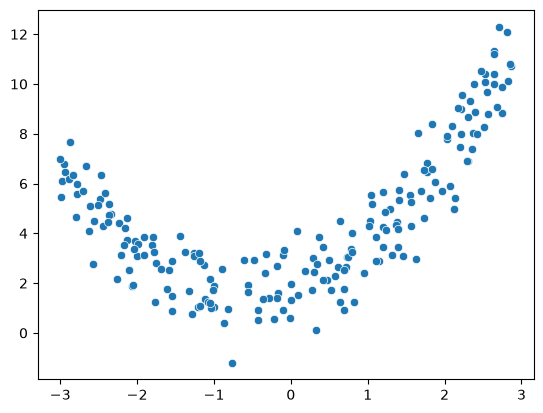

In [11]:
import seaborn as sns
sns.scatterplot(x=X.ravel(),y=y.ravel())

In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=2)

In [13]:
lr=LinearRegression()

In [14]:
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.91]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[4.37]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[22.01]


In [15]:
r2_score(y_test,lr.predict(X_test))

0.03522948329549358

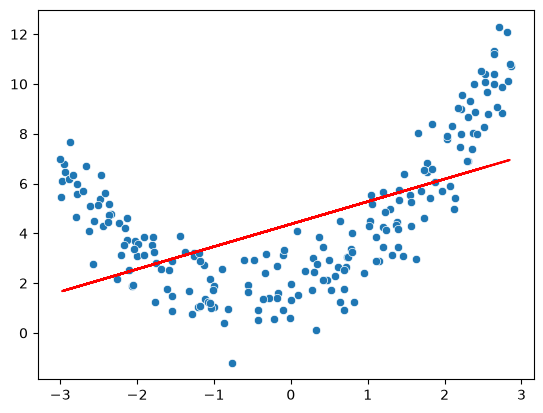

In [17]:
sns.scatterplot(x=X.ravel(),y=y.ravel())
plt.plot(X_test,lr.predict(X_test),color='r')

In [52]:

poly=PolynomialFeatures(degree=2)
X_train_trans=poly.fit_transform(X_train)
X_test_trans=poly.transform(X_test)

In [53]:
"""

- fit_transform(): Learns the transformation setup and transforms the data.
- transform(): Applies an already-established transformation to the data.
transform = apply a specific operation to change the structure or values of your data.(without changing the actual sample)

fit() means learning or determining the necessary settings from your data before transforming it.

fit() = learn the settings; transform() = apply those settings to the data.
fit() establishes the transformation setup.
What fit() learns depends on the transformer or model you're using.
In your PolynomialFeatures example, fit() determines the polynomial feature structure. In StandardScaler, fit() learns the mean and standard deviation from the training data.
transform() applies that setup to the data.
fit_transform() does both in one step.


https://chatgpt.com/s/t_6adf1f47d1cc8191aea06c2192d39af0
"""

"\n\n- fit_transform(): Learns the transformation setup and transforms the data.\n- transform(): Applies an already-established transformation to the data.\ntransform = apply a specific operation to change the structure or values of your data.(without changing the actual sample)\n\nfit() means learning or determining the necessary settings from your data before transforming it.\n\nfit() = learn the settings; transform() = apply those settings to the data.\nfit() establishes the transformation setup.\nWhat fit() learns depends on the transformer or model you're using.\nIn your PolynomialFeatures example, fit() determines the polynomial feature structure. In StandardScaler, fit() learns the mean and standard deviation from the training data.\ntransform() applies that setup to the data.\nfit_transform() does both in one step.\n\n\nhttps://chatgpt.com/s/t_6adf1f47d1cc8191aea06c2192d39af0\n"

In [54]:
print(X_train[0])
print(X_train_trans[0])
print(X_test[0])
print(X_test_trans[0])

[-2.16591009]
[ 1.         -2.16591009  4.69116651]
[2.12886089]
[1.         2.12886089 4.53204868]


In [55]:
lr.fit(X_train_trans,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 3)","[[0. ,0.92,0.84]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[1.82]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,2
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[32.45,22.01, 0. ]"


In [56]:
r2_score(y_test,lr.predict(X_test_trans))

0.8321558106273036

In [57]:
lr.coef_

array([[0.        , 0.91676101, 0.84347805]])

C:\Users\User\AppData\Local\Temp\ipykernel_11004\669152478.py:3: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ".b" (-> color='b'). The keyword argument will take precedence.
  plt.plot(X_test, lr.predict(X_test_trans),'.b', color='red')


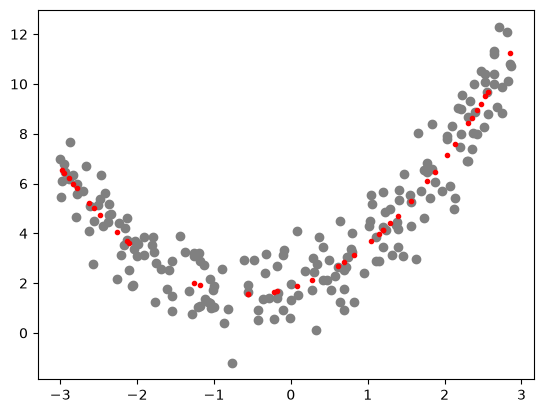

In [58]:
plt.scatter(X.ravel(), y.ravel(), color='gray')

plt.plot(X_test, lr.predict(X_test_trans),'.b', color='red')

plt.show()

In [51]:
# check the model by changing degrres